In [1]:
import sys
sys.dont_write_bytecode = True

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error as mse, root_mean_squared_error as rmse, r2_score as r2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import mixed_precision, Model
from tensorflow.keras.models import load_model
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, GRU, LSTM, Input, Dropout, RepeatVector, LayerNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)

I0000 00:00:1795523349.030370     859 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795523349.531312     859 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795523351.539878     859 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# VERIFY TRAINING CAPABILITIES

gpus = tf.config.list_physical_devices('GPU')
if gpus:
  for gpu in gpus:
    details = tf.config.experimental.get_device_details(gpu)
    print("Device Name:", details.get("device_name", "Unknown"))
    print("Compute Capability:", details.get("compute_capability", "Unknown"))

policy = tf.keras.mixed_precision.global_policy()
print("Current global policy:", policy.name)
print("Compute dtype:", policy.compute_dtype)
print("Variable dtype:", policy.variable_dtype)

Device Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Compute Capability: (8, 6)
Current global policy: mixed_float16
Compute dtype: float16
Variable dtype: float32


In [ ]:
# GLOBAL SETTINGS

MDL_SAVE_DIR = "LSTM_Encoder_Decoder.keras"
MDL_LOAD_DIR = "LSTM_Encoder_Decoder.keras"

TARGET_FEATURE = "cnt"
PAST_FEATURES = ['hr', 'atemp', 'hum', 'mnth', 'holiday', 'workingday', 'weathersit', 'cnt']
FUTURE_FEATURES = ['hr', 'atemp', 'hum', 'mnth', 'holiday', 'workingday', 'weathersit']

TIMESTEPS_IN = 24*7
TIMESTEPS_OUT = 24

NORMALIZE = True

BATCH_SIZE = 16
EPOCHS = 40
LEARNING_RATE = 0.001

EARLY_STOPPING_PATIENCE = 6

REDUCE_LR_PATIENCE = 2
REDUCE_LR_FACTOR = 0.5
REDUCE_LR_MIN = 0.0001

In [6]:
# HELPER FUNCTIONS

# Loading dataset on chosen features + correcting data types
def corrected_read_csv(path, verify=False):
    df = pd.read_csv(path)
    df = df[["dteday"] + PAST_FEATURES]
    cols = df.columns
    df[cols[0]] = pd.to_datetime(df[cols[0]], format='mixed')
    for c in cols[1:]:
        if df[c].dtype == "float64": df[c] = df[c].astype('float32')
        if df[c].dtype == "int64": df[c] = df[c].astype('int32')
    
    if verify: display(df.info())

    return df


# Split the dataframe into data sequences
def split_sequences(mtx, strides=1):
    X_past = []
    X_future = []
    y = []

    target_idx = PAST_FEATURES.index(TARGET_FEATURE)

    for i in range(0, mtx.shape[0] - TIMESTEPS_IN - TIMESTEPS_OUT + 1, strides):
        X_past.append(mtx[i : i+TIMESTEPS_IN])

        future_seq = mtx[i+TIMESTEPS_IN : i+TIMESTEPS_IN+TIMESTEPS_OUT]
        
        X_future.append(np.delete(future_seq, target_idx, axis=1))
        y.append(future_seq[:, target_idx].reshape(-1,1))
    
    return np.array(X_past).astype('float32'), np.array(X_future).astype('float32'), np.array(y).astype('float32')


# Custom R2 score for output of sequences
class SequenceR2Score(tf.keras.metrics.R2Score):
    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.reshape(y_true, [-1, 1])
        y_pred = tf.reshape(y_pred, [-1, 1])
        
        if sample_weight is not None:
            sample_weight = tf.reshape(sample_weight, [-1, 1])
            
        return super().update_state(y_true, y_pred, sample_weight=sample_weight)


# Results
def result_report(y_true, y_pred):
    print(f"""
================================
    MAE: {mae(y_true, y_pred):.4f}
    MSE: {mse(y_true, y_pred):.4f}
    RMSE: {rmse(y_true, y_pred):.4f}
    R2: {r2(y_true, y_pred):.4f}
================================
    """)

In [7]:
# IMPORT DATASETS

raw_trains = corrected_read_csv("data/hour_train.csv", verify=True)
raw_vals = corrected_read_csv("data/hour_val.csv", verify=True)
raw_tests = corrected_read_csv("data/hour_test.csv", verify=True)

<class 'pandas.DataFrame'>
RangeIndex: 13034 entries, 0 to 13033
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      13034 non-null  datetime64[us]
 1   hr          13034 non-null  int32         
 2   atemp       13034 non-null  float32       
 3   hum         13034 non-null  float32       
 4   mnth        13034 non-null  int32         
 5   holiday     13034 non-null  int32         
 6   workingday  13034 non-null  int32         
 7   weathersit  13034 non-null  int32         
 8   cnt         13034 non-null  int32         
dtypes: datetime64[us](1), float32(2), int32(6)
memory usage: 509.3 KB


None

<class 'pandas.DataFrame'>
RangeIndex: 1738 entries, 0 to 1737
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      1738 non-null   datetime64[us]
 1   hr          1738 non-null   int32         
 2   atemp       1738 non-null   float32       
 3   hum         1738 non-null   float32       
 4   mnth        1738 non-null   int32         
 5   holiday     1738 non-null   int32         
 6   workingday  1738 non-null   int32         
 7   weathersit  1738 non-null   int32         
 8   cnt         1738 non-null   int32         
dtypes: datetime64[us](1), float32(2), int32(6)
memory usage: 68.0 KB


None

<class 'pandas.DataFrame'>
RangeIndex: 2607 entries, 0 to 2606
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      2607 non-null   datetime64[us]
 1   hr          2607 non-null   int32         
 2   atemp       2607 non-null   float32       
 3   hum         2607 non-null   float32       
 4   mnth        2607 non-null   int32         
 5   holiday     2607 non-null   int32         
 6   workingday  2607 non-null   int32         
 7   weathersit  2607 non-null   int32         
 8   cnt         2607 non-null   int32         
dtypes: datetime64[us](1), float32(2), int32(6)
memory usage: 102.0 KB


None

In [ ]:
# "BRIDGE THE GAP"

# The last N (= TIMESTEP_IN) rows of the training set are added to the head of the validation set, do the same for validation-test pair.
# Purpose: to avoid skipping N first timesteps in validation & training sets during inference phase.
# Important note: this action does not cause data leakage because that sequence (that N rows) is not used to train model

trains = raw_trains.copy(deep=True)
vals = pd.concat([trains[-TIMESTEPS_IN:], raw_vals])
tests = pd.concat([vals[-TIMESTEPS_IN:], raw_tests])

In [36]:
display(vals.shape)
display(tests.shape)
display(vals.info())

(1906, 9)

(2775, 9)

<class 'pandas.DataFrame'>
Index: 1906 entries, 12866 to 1737
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      1906 non-null   datetime64[us]
 1   hr          1906 non-null   int32         
 2   atemp       1906 non-null   float32       
 3   hum         1906 non-null   float32       
 4   mnth        1906 non-null   int32         
 5   holiday     1906 non-null   int32         
 6   workingday  1906 non-null   int32         
 7   weathersit  1906 non-null   int32         
 8   cnt         1906 non-null   int32         
dtypes: datetime64[us](1), float32(2), int32(6)
memory usage: 89.3 KB


None

In [17]:
# NORMALIZE

std_trains = trains[PAST_FEATURES].values
std_vals = vals[PAST_FEATURES].values
std_tests = tests[PAST_FEATURES].values

if NORMALIZE:
    #scaler = MinMaxScaler(feature_range=(0,1)).fit(trains[TARGET_FEATURE].values.reshape(-1,1))
    #target_idx = PAST_FEATURES.index(TARGET_FEATURE)
    #std_trains[:, target_idx] = scaler.transform(trains[TARGET_FEATURE].values.reshape(-1,1)).flatten()
    #std_vals[:, target_idx] = scaler.transform(vals[TARGET_FEATURE].values.reshape(-1,1)).flatten()
    #std_tests[:, target_idx] = scaler.transform(tests[TARGET_FEATURE].values.reshape(-1,1)).flatten()

    scaler = StandardScaler().fit(trains[PAST_FEATURES])
    std_trains = scaler.transform(trains[PAST_FEATURES])
    std_vals = scaler.transform(vals[PAST_FEATURES])
    std_tests = scaler.transform(tests[PAST_FEATURES])


In [18]:
print(std_trains)
print()
print(std_trains[24*72+20])
print(std_trains.shape)
print(std_vals.shape)
print(std_tests.shape)

[[-1.67100511 -1.022532    0.93474608 ... -1.47013276 -0.65771996
  -0.94392905]
 [-1.52633732 -1.11114291  0.8846819  ... -1.47013276 -0.65771996
  -0.7946514 ]
 [-1.38166953 -1.11114291  0.8846819  ... -1.47013276 -0.65771996
  -0.84441062]
 ...
 [-1.09233395  1.18574654 -0.41698796 ...  0.68021068  0.88663636
  -0.96880866]
 [-0.94766616  1.18574654 -0.56718079 ...  0.68021068  0.88663636
  -0.7946514 ]
 [-0.80299836  1.09713546 -0.21673124 ...  0.68021068 -0.65771996
  -0.19754082]]

[ 0.20967617  0.92049672 -1.06782303 -0.77281905 -0.1678131   0.68021068
 -0.65771996  0.04503535]
(13034, 8)
(1906, 8)
(2775, 8)


In [19]:
# SPLIT THE DATASETS INTO SEQUENCES

X_past_trains, X_future_trains, y_trains = split_sequences(std_trains, 2)
X_past_vals, X_future_vals, y_vals = split_sequences(std_vals, 1)
X_past_tests, X_future_tests, y_tests = split_sequences(std_tests, 1)

In [20]:
# VERIFY DIMENSIONS OF SEQUENCE SETS

def check_dimensions(X_past, X_future, y):
    print(f"{X_past.dtype} {X_past.shape}  |  {X_future.dtype} {X_future.shape}  |  {y.dtype} {y.shape}")

check_dimensions(X_past_trains, X_future_trains, y_trains)
check_dimensions(X_past_vals, X_future_vals, y_vals)
check_dimensions(X_past_tests, X_future_tests, y_tests)

float32 (6422, 168, 8)  |  float32 (6422, 24, 7)  |  float32 (6422, 24, 1)
float32 (1715, 168, 8)  |  float32 (1715, 24, 7)  |  float32 (1715, 24, 1)
float32 (2584, 168, 8)  |  float32 (2584, 24, 7)  |  float32 (2584, 24, 1)


In [21]:
# MODEL DESIGN

tf.keras.backend.clear_session()

def encoder_decoder_seq2seq():
    # Inputs
    past = Input(shape=(TIMESTEPS_IN, len(PAST_FEATURES)), name="Past")
    future = Input(shape=(TIMESTEPS_OUT, len(FUTURE_FEATURES)), name="Known_future")

    norm_past = LayerNormalization(epsilon=1e-3)(past)
    norm_future = LayerNormalization(epsilon=1e-3)(future)

    # Encoder
    _, state_h, state_c = LSTM(name="Encoder",
        units=128, activation='gelu', return_sequences=False, return_state=True,
        kernel_initializer='he_normal', bias_initializer='zeros', recurrent_initializer='orthogonal',
        kernel_regularizer=l2(0.001), bias_regularizer=l2(0.001), dropout=0.2
    )(norm_past)

    # Bottleneck
    context_vector = [LayerNormalization(epsilon=1e-3)(state_h), LayerNormalization(epsilon=1e-3)(state_c)]

    # Decoder
    de_seq = LSTM(name="Decoder",
        units=128, activation='gelu', return_sequences=True, return_state=False,
        kernel_initializer='he_normal', bias_initializer='zeros', recurrent_initializer='orthogonal',
        kernel_regularizer=l2(0.001), bias_regularizer=l2(0.001), dropout=0.2
    )(norm_future, initial_state=context_vector)

    norm_de_seq = LayerNormalization(epsilon=1e-3)(de_seq)

    # Output
    outputs = Dense(1, name="Output", dtype='float32')(norm_de_seq)

    return Model(inputs=[past, future], outputs=outputs, name="LSTM_Encoder_Decoder")


mdl = encoder_decoder_seq2seq()

mdl.compile(optimizer=Adam(learning_rate=LEARNING_RATE, beta_1=0.9, beta_2=0.99, clipnorm=1.0), loss="mse", metrics=["mae", SequenceR2Score()], jit_compile=True)

mdl.summary()

Model: "LSTM_Encoder_Decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Past (InputLayer)   │ (None, 168, 8)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 168, 8)    │         16 │ Past[0][0]        │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Known_future        │ (None, 24, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Encoder (LSTM)      │ [(None, 128),     │     70,144 │ layer_normalizat… │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 7)     │         14 │ Known_future[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128)       │        256 │ Encoder[0][1]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128)       │        256 │ Encoder[0][2]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Decoder (LSTM)      │ (None, 24, 128)   │     69,632 │ layer_normalizat… │
│                     │                   │            │ layer_normalizat… │
│                     │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 128)   │        256 │ Decoder[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Output (Dense)      │ (None, 24, 1)     │        129 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 140,703 (549.62 KB)

 Trainable params: 140,703 (549.62 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# START TRAINING PROCESS

history = mdl.fit(
    {"Past": X_past_trains, "Known_future":X_future_trains},
    y_trains,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    verbose=1,
    shuffle=False,
    validation_data=(
        {"Past": X_past_vals, "Known_future":X_future_vals},
        y_vals
    ),
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE, min_lr=REDUCE_LR_MIN),
    ]
)
mdl.save(MDL_SAVE_DIR)

Epoch 1/40


I0000 00:00:1795523833.710506    1468 dot_merger.cc:481] Merging Dots in computation: LSTM_Encoder_Decoder_1_Decoder_1_while_body_24199_grad_24667_const_0__.57.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1795523833.710677    1468 dot_merger.cc:481] Merging Dots in computation: LSTM_Encoder_Decoder_1_Encoder_1_while_body_23925_grad_25489_const_0__.85.clone.clone.clone.clone.clone.clone.clone.clone


400/402 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 2.5505 - mae: 0.5506 - r2_score: 0.4451

I0000 00:00:1795523854.632480    1466 dot_merger.cc:481] Merging Dots in computation: LSTM_Encoder_Decoder_1_Decoder_1_while_body_24199_grad_24667_const_0__.57.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1795523854.632639    1466 dot_merger.cc:481] Merging Dots in computation: LSTM_Encoder_Decoder_1_Encoder_1_while_body_23925_grad_25489_const_0__.85.clone.clone.clone.clone.clone.clone.clone.clone


402/402 ━━━━━━━━━━━━━━━━━━━━ 32s 61ms/step - loss: 2.5488 - mae: 0.5506 - r2_score: 0.4455 - val_loss: 2.4372 - val_mae: 0.6387 - val_r2_score: 0.5523 - learning_rate: 0.0010
Epoch 2/40
402/402 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - loss: 1.5539 - mae: 0.4154 - r2_score: 0.6529 - val_loss: 1.6001 - val_mae: 0.5670 - val_r2_score: 0.6388 - learning_rate: 0.0010
Epoch 3/40
402/402 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - loss: 0.9740 - mae: 0.3843 - r2_score: 0.6903 - val_loss: 1.0590 - val_mae: 0.5271 - val_r2_score: 0.6882 - learning_rate: 0.0010
Epoch 4/40
402/402 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - loss: 0.6126 - mae: 0.3715 - r2_score: 0.7049 - val_loss: 0.8104 - val_mae: 0.5042 - val_r2_score: 0.6979 - learning_rate: 0.0010
Epoch 5/40
402/402 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - loss: 0.4701 - mae: 0.3653 - r2_score: 0.7156 - val_loss: 0.4672 - val_mae: 0.3818 - val_r2_score: 0.8410 - learning_rate: 0.0010
Epoch 6/40
402/402 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - loss: 0.3620 - mae: 0.321

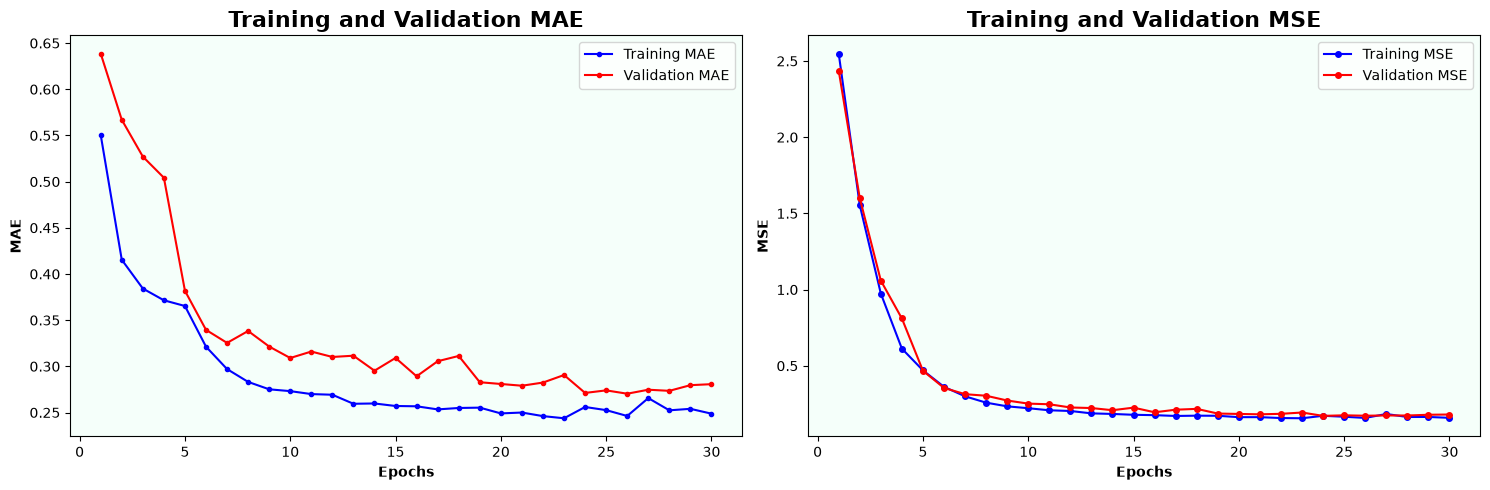

In [23]:
# HISTORY OF TRAINING LOSSES

acc = history.history['mae']
val_acc = history.history['val_mae']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training MAE', markersize=3)
plt.plot(epochs, val_acc, 'ro-', label='Validation MAE', markersize=3)
plt.title('Training and Validation MAE', fontweight='bold', size=16)
plt.xlabel('Epochs', fontweight='bold')
plt.ylabel('MAE', fontweight='bold')
#plt.ylim(0, 1)
plt.gca().set_facecolor('#F5FFFA')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'bo-', label='Training MSE', markersize=4)
plt.plot(epochs, val_loss, 'ro-', label='Validation MSE', markersize=4)
plt.title('Training and Validation MSE', fontweight='bold', size=16)
plt.xlabel('Epochs', fontweight='bold')
plt.ylabel('MSE', fontweight='bold')
#plt.ylim(0, 1)
plt.gca().set_facecolor('#F5FFFA')
plt.legend()

plt.tight_layout()
plt.show()


In [24]:
# LOAD THE TRAINED MODEL

mdll = load_model(MDL_LOAD_DIR, compile=False)

In [25]:
# PREDICTION

y_preds = mdl.predict({"Past": X_past_tests, "Known_future":X_future_tests})
print(y_preds.shape)

81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step
(2584, 24, 1)


In [ ]:
# INVERSE TRANSFORM INTO THE ORIGINAL SCALE

#org_y_preds = scaler.inverse_transform(y_preds.reshape(-1, 1)).reshape(y_preds.shape[0], TIMESTEPS_OUT, 1)
#org_y_tests = scaler.inverse_transform(y_tests.reshape(-1, 1)).reshape(y_tests.shape[0], TIMESTEPS_OUT, 1)

if NORMALIZE:
    scl_mean = scaler.mean_[PAST_FEATURES.index(TARGET_FEATURE)]
    scl_std = scaler.scale_[PAST_FEATURES.index(TARGET_FEATURE)]

    org_y_preds = ((y_preds * scl_std) + scl_mean)
    org_y_tests = ((y_tests * scl_std) + scl_mean)
else:
    org_y_preds = y_preds
    org_y_tests = y_tests

In [27]:
# COMPILE RESULTS

result_report(org_y_tests.ravel(), org_y_preds.ravel())


    MAE: 56.7139
    MSE: 6950.2896
    RMSE: 83.3684
    R2: 0.8491
    


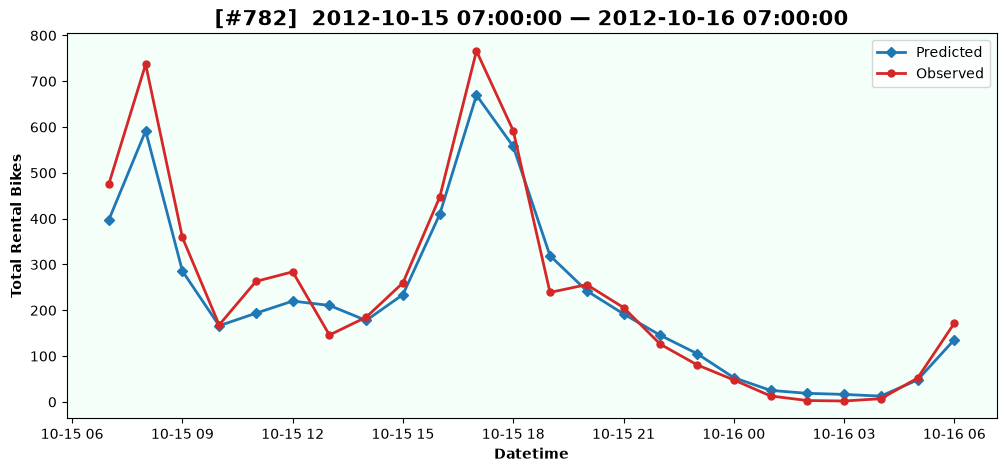

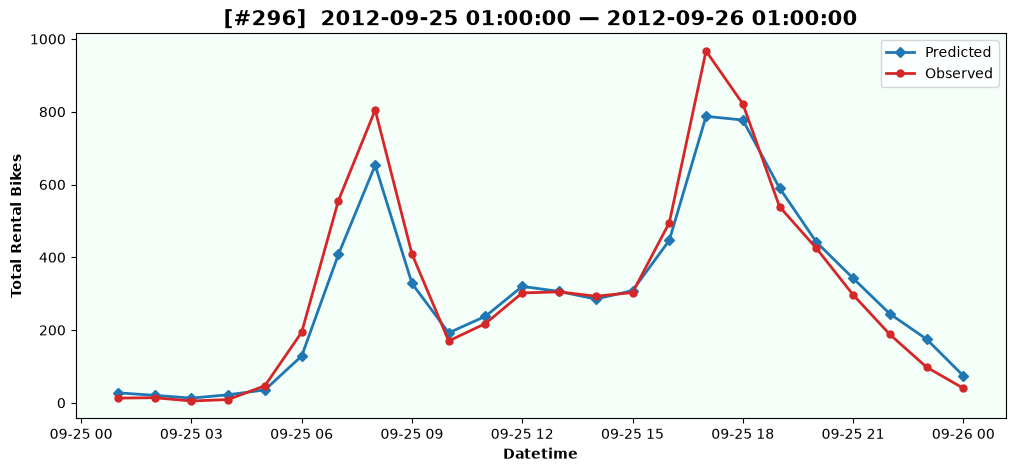

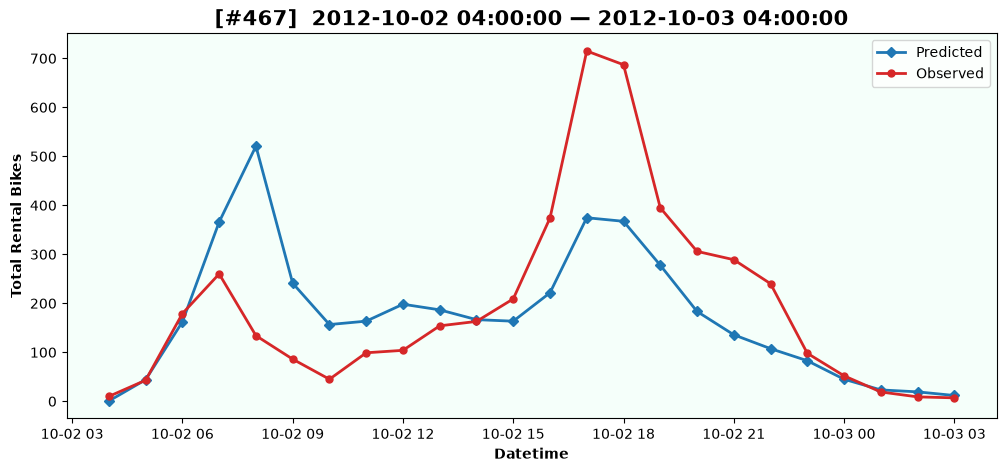

In [32]:
# VISUALIZE RESULTS

for _ in range(3):
    d = random.randint(0, raw_tests.shape[0]-TIMESTEPS_OUT)
    fig, ax = plt.subplots(figsize=(12,5))

    ax.set_title(f"[#{d}]  {raw_tests['dteday'][d]} — {raw_tests['dteday'][d+TIMESTEPS_OUT]}", size=15, fontweight='bold')
    ax.plot(raw_tests['dteday'][d:d+TIMESTEPS_OUT], org_y_preds[d], label='Predicted', color='tab:blue', lw=2, marker='D', markersize=5)
    ax.plot(raw_tests['dteday'][d:d+TIMESTEPS_OUT], org_y_tests[d], label='Observed', color='tab:red', lw=2, marker='o', markersize=5)

    ax.set_xlabel('Datetime', fontweight='bold')
    ax.set_ylabel('Total Rental Bikes', fontweight='bold')
    ax.set_facecolor('#F5FFFA')
    ax.legend()
